<a href="https://colab.research.google.com/github/vidyashiremath/Forest-Fire-Risk-Classification/blob/main/Forest_Fire_Risk_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Install/import libraries

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import pickle

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
        precision_score,
            recall_score,
                f1_score,
                    confusion_matrix,
                        classification_report,
                            roc_auc_score,
                                RocCurveDisplay
                                )

warnings.filterwarnings("ignore")

In [8]:
uploaded = files.upload()

Saving Algerian_forest_fires_dataset.csv to Algerian_forest_fires_dataset (1).csv


In [9]:
filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (247, 14)


,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes
0,1,6,2012,29,57,18,0,65.7,3.4,7.6,1.3,3.4,0.5,not fire
1,2,6,2012,29,61,13,1.3,64.4,4.1,7.6,1,3.9,0.4,not fire
2,3,6,2012,26,82,22,13.1,47.1,2.5,7.1,0.3,2.7,0.1,not fire
3,4,6,2012,25,89,13,2.5,28.6,1.3,6.9,0,1.7,0,not fire
4,5,6,2012,27,77,16,0,64.8,3,14.2,1.2,3.9,0.5,not fire


In [10]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

Number of rows: 247
Number of columns: 14

Column names:
['day', 'month', 'year', 'Temperature', ' RH', ' Ws', 'Rain ', 'FFMC', 'DMC', 'DC', 'ISI', 'BUI', 'FWI', 'Classes  ']


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 247 entries, 0 to 246
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   day          246 non-null    object
 1   month        245 non-null    object
 2   year         245 non-null    object
 3   Temperature  245 non-null    object
 4    RH          245 non-null    object
 5    Ws          245 non-null    object
 6   Rain         245 non-null    object
 7   FFMC         245 non-null    object
 8   DMC          245 non-null    object
 9   DC           245 non-null    object
 10  ISI          245 non-null    object
 11  BUI          245 non-null    object
 12  FWI          245 non-null    object
 13  Classes      244 non-null    object
dtypes: object(14)
memory usage: 27.1+ KB


In [12]:
df.describe()

,day,month,year,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Classes
count,246,245,245,245,245,245,245,245,245,245,245,245,245,244
unique,33,5,2,20,63,19,40,174,167,199,107,175,127,9
top,1,7,2012,35,55,14,0,88.9,7.9,8,1.1,3,0.4,fire
freq,8,62,244,29,10,43,133,8,5,5,8,5,12,131


Clean column names

In [13]:
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['day', 'month', 'year', 'Temperature', 'RH', 'Ws', 'Rain', 'FFMC', 'DMC', 'DC', 'ISI', 'BUI', 'FWI', 'Classes']


 Check missing values

In [14]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
day            1
month          2
year           2
Temperature    2
RH             2
Ws             2
Rain           2
FFMC           2
DMC            2
DC             2
ISI            2
BUI            2
FWI            2
Classes        3
dtype: int64


 Check duplicates

In [15]:
print("Number of duplicate rows:")
print(df.duplicated().sum())

Number of duplicate rows:
0


In [16]:
df = df.drop_duplicates()

print("Shape after removing duplicates:")
print(df.shape)

Shape after removing duplicates:
(247, 14)


 Check target

In [17]:
print(df["Classes"].value_counts())

Classes
fire             131
not fire         101
fire               4
fire               2
not fire           2
not fire           1
Classes            1
not fire           1
not fire           1
Name: count, dtype: int64


Clean target values

In [18]:
df["Classes"] = df["Classes"].astype(str).str.strip().str.lower()

print(df["Classes"].value_counts())

Classes
fire        137
not fire    106
nan           3
classes       1
Name: count, dtype: int64


Class distribution


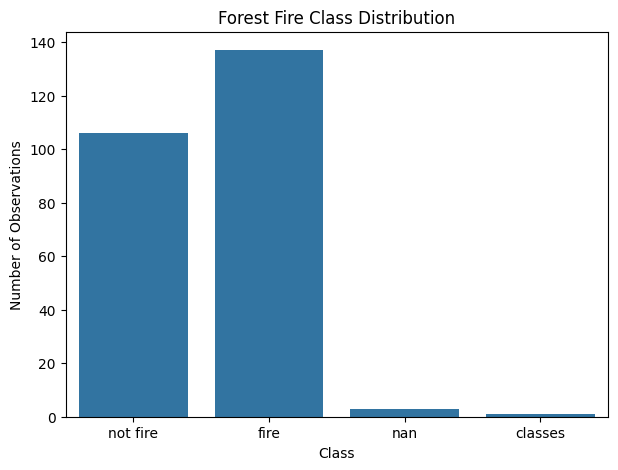

In [19]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x="Classes")

plt.title("Forest Fire Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Observations")

plt.show()

Convert numerical columns

In [20]:
for column in df.columns:
      if column != "Classes":
              df[column] = pd.to_numeric(
                          df[column].astype(str).str.strip(),
                                      errors="coerce"
                                              )

In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 247 entries, 0 to 246
Data columns (total 14 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   day          244 non-null    float64
 1   month        244 non-null    float64
 2   year         244 non-null    float64
 3   Temperature  244 non-null    float64
 4   RH           244 non-null    float64
 5   Ws           244 non-null    float64
 6   Rain         244 non-null    float64
 7   FFMC         244 non-null    float64
 8   DMC          244 non-null    float64
 9   DC           243 non-null    float64
 10  ISI          244 non-null    float64
 11  BUI          244 non-null    float64
 12  FWI          243 non-null    float64
 13  Classes      247 non-null    object 
dtypes: float64(13), object(1)
memory usage: 27.1+ KB


 Handle missing values


In [22]:
print("Missing values before treatment:")
print(df.isnull().sum())

Missing values before treatment:
day            3
month          3
year           3
Temperature    3
RH             3
Ws             3
Rain           3
FFMC           3
DMC            3
DC             4
ISI            3
BUI            3
FWI            4
Classes        0
dtype: int64


In [23]:
numeric_columns = df.select_dtypes(include=np.number).columns

for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())

In [24]:
print("Missing values after treatment:")
print(df.isnull().sum())

Missing values after treatment:
day            0
month          0
year           0
Temperature    0
RH             0
Ws             0
Rain           0
FFMC           0
DMC            0
DC             0
ISI            0
BUI            0
FWI            0
Classes        0
dtype: int64


 Distribution of numerical features

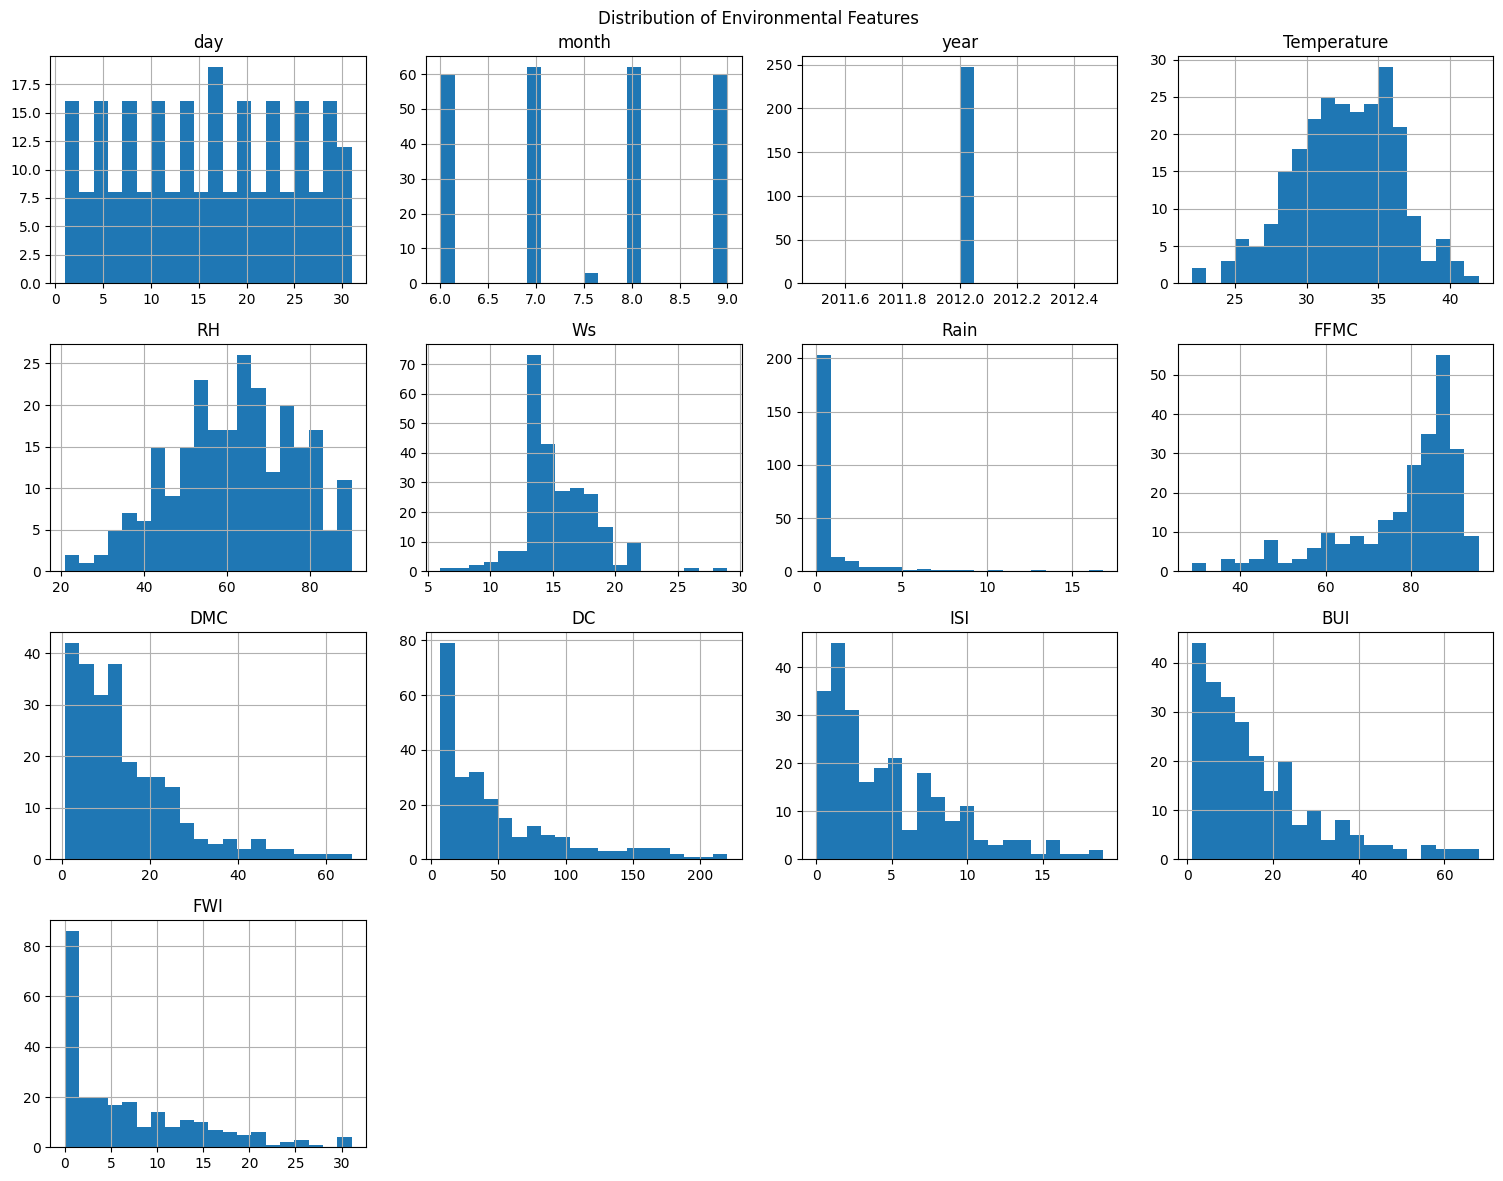

In [26]:
df[numeric_columns].hist(
      figsize=(15,12),
          bins=20
          )

plt.suptitle("Distribution of Environmental Features")
plt.tight_layout()
plt.show()


Outlier analysis

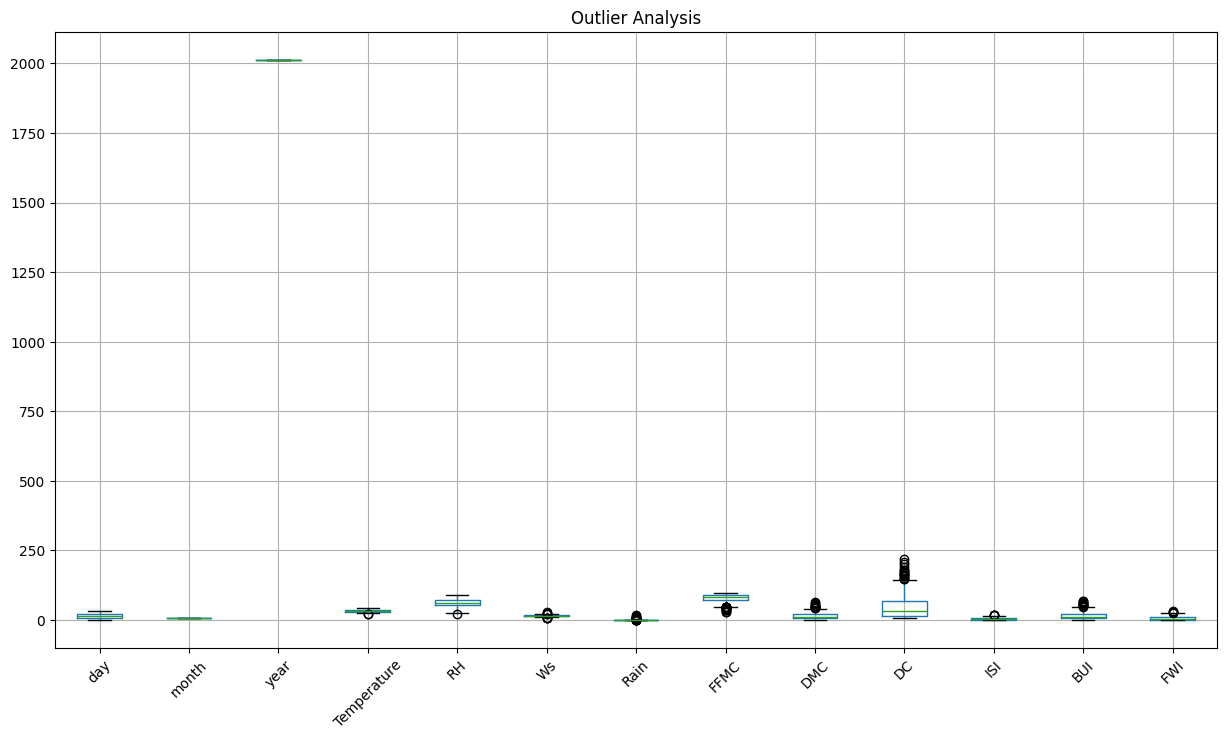

In [27]:
plt.figure(figsize=(15,8))

df[numeric_columns].boxplot()

plt.title("Outlier Analysis")
plt.xticks(rotation=45)

plt.show()

Correlation heatmap


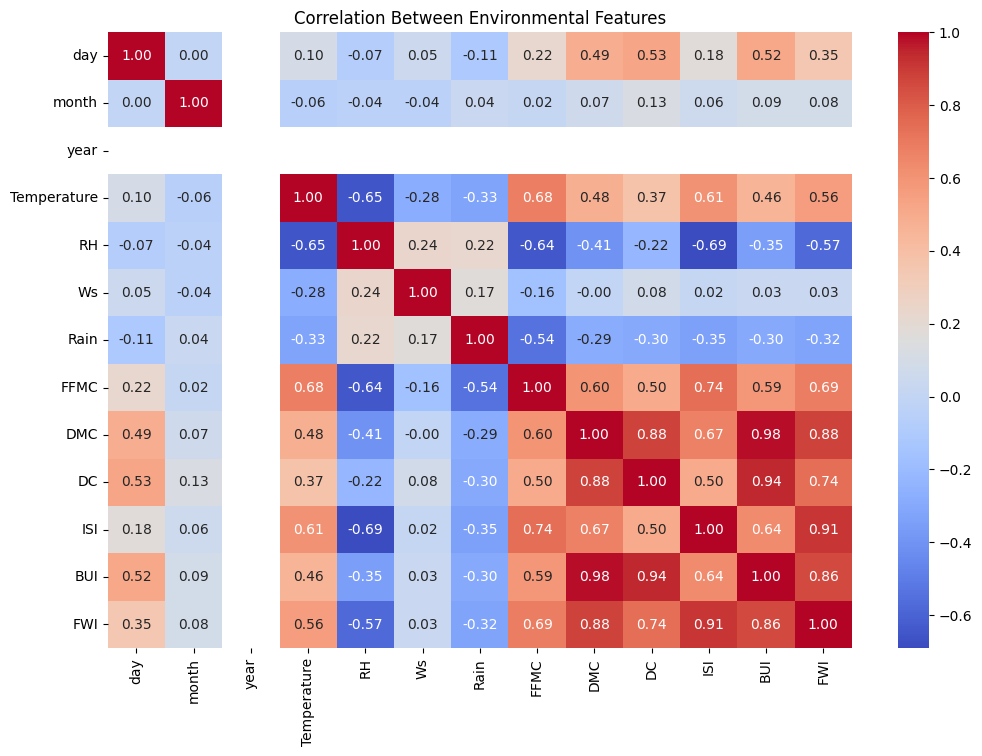

In [29]:
plt.figure(figsize=(12,8))

correlation = df[numeric_columns].corr()

sns.heatmap(
    correlation,
        annot=True,
            fmt=".2f",
                cmap="coolwarm"
                )

plt.title("Correlation Between Environmental Features")

plt.show()

 Relationship with fire class

In [31]:
df["Fire_Label"] = df["Classes"].map({
      "not fire": 0,
          "fire": 1
          })

print(df[["Classes", "Fire_Label"]].head())


    Classes  Fire_Label
0  not fire         0.0
1  not fire         0.0
2  not fire         0.0
3  not fire         0.0
4  not fire         0.0


 Select features

In [35]:
features = [
      "Temperature",
          "RH",
              "Ws",
                  "Rain",
                      "FFMC",
                          "DMC",
                              "DC",
                                  "ISI",
                                      "BUI",
                                          "FWI"
                                          ]


In [36]:
print("Available features:")

for feature in features:
    print(feature, "->", feature in df.columns)

Available features:
Temperature -> True
RH -> True
Ws -> True
Rain -> True
FFMC -> True
DMC -> True
DC -> True
ISI -> True
BUI -> True
FWI -> True


Create X and y

In [37]:
X = df[features]

y = df["Fire_Label"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (247, 10)
y shape: (247,)


Train-test split

In [87]:
X_train, X_test, y_train, y_test = train_test_split(
      X,
          y,
              test_size=0.20,
                  random_state=42,
                      stratify=y
                      )

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (194, 10)
Testing data: (49, 10)


In [41]:
print("Missing values in 'Fire_Label' before dropping:")
print(y.isnull().sum())

df.dropna(subset=['Fire_Label'], inplace=True)
X = df[features]
y = df['Fire_Label']

print("Missing values in 'Fire_Label' after dropping:")
print(y.isnull().sum())

Missing values in 'Fire_Label' before dropping:
4
Missing values in 'Fire_Label' after dropping:
0


In [42]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (194, 10)
Testing data: (49, 10)


 Logistic Regression

In [43]:
logistic_model = Pipeline([
      ("scaler", StandardScaler()),
          ("model", LogisticRegression(max_iter=1000))
          ])

logistic_model.fit(X_train, y_train)

y_pred_lr = logistic_model.predict(X_test)


In [45]:
print("LOGISTIC REGRESSION")
print("-------------------")

print("Accuracy:",
      accuracy_score(y_test, y_pred_lr))

print("Precision:",
            precision_score(y_test, y_pred_lr))

print("Recall:",
                  recall_score(y_test, y_pred_lr))

print("F1 Score:",
                        f1_score(y_test, y_pred_lr))

LOGISTIC REGRESSION
-------------------
Accuracy: 0.9387755102040817
Precision: 0.9310344827586207
Recall: 0.9642857142857143
F1 Score: 0.9473684210526315


 Logistic Regression ROC-AUC


In [46]:
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

roc_auc_lr = roc_auc_score(y_test, y_prob_lr)

print("ROC-AUC:", roc_auc_lr)

ROC-AUC: 0.9931972789115646


KNN

In [48]:
knn_model = Pipeline([
      ("scaler", StandardScaler()),
          ("model", KNeighborsClassifier(n_neighbors=5))
          ])

knn_model.fit(X_train, y_train)

y_pred_knn = knn_model.predict(X_test)

In [50]:
print("KNN")
print("---")

print("Accuracy:",
      accuracy_score(y_test, y_pred_knn))

print("Precision:",
            precision_score(y_test, y_pred_knn))

print("Recall:",
                  recall_score(y_test, y_pred_knn))

print("F1 Score:",
                        f1_score(y_test, y_pred_knn))

KNN
---
Accuracy: 0.8775510204081632
Precision: 0.8928571428571429
Recall: 0.8928571428571429
F1 Score: 0.8928571428571429


KNN ROC-AUC

In [51]:
y_prob_knn = knn_model.predict_proba(X_test)[:, 1]

roc_auc_knn = roc_auc_score(y_test, y_prob_knn)

print("ROC-AUC:", roc_auc_knn)

ROC-AUC: 0.9761904761904762


Decision Tree

In [53]:
tree_model = DecisionTreeClassifier(
      random_state=42,
          max_depth=5
          )

tree_model.fit(X_train, y_train)

y_pred_tree = tree_model.predict(X_test)


In [55]:
print("DECISION TREE")
print("-------------")

print("Accuracy:",
      accuracy_score(y_test, y_pred_tree))

print("Precision:",
            precision_score(y_test, y_pred_tree))

print("Recall:",
                  recall_score(y_test, y_pred_tree))

print("F1 Score:",
                        f1_score(y_test, y_pred_tree))

DECISION TREE
-------------
Accuracy: 0.9591836734693877
Precision: 0.9333333333333333
Recall: 1.0
F1 Score: 0.9655172413793104


 Decision Tree ROC-AUC

In [56]:
y_prob_tree = tree_model.predict_proba(X_test)[:, 1]

roc_auc_tree = roc_auc_score(y_test, y_prob_tree)

print("ROC-AUC:", roc_auc_tree)

ROC-AUC: 0.9523809523809523


Compare all models

In [58]:
results = pd.DataFrame({
      "Model": [
              "Logistic Regression",
                      "KNN",
                              "Decision Tree"
                                  ],

                                          "Accuracy": [
                                                  accuracy_score(y_test, y_pred_lr),
                                                          accuracy_score(y_test, y_pred_knn),
                                                                  accuracy_score(y_test, y_pred_tree)
                                                                      ],

                                                                              "Precision": [
                                                                                      precision_score(y_test, y_pred_lr),
                                                                                              precision_score(y_test, y_pred_knn),
                                                                                                      precision_score(y_test, y_pred_tree)
                                                                                                          ],

                                                                                                                  "Recall": [
                                                                                                                          recall_score(y_test, y_pred_lr),
                                                                                                                                  recall_score(y_test, y_pred_knn),
                                                                                                                                          recall_score(y_test, y_pred_tree)
                                                                                                                                              ],

                                                                                                                                                      "F1 Score": [
                                                                                                                                                              f1_score(y_test, y_pred_lr),
                                                                                                                                                                      f1_score(y_test, y_pred_knn),
                                                                                                                                                                              f1_score(y_test, y_pred_tree)
                                                                                                                                                                                  ],

                                                                                                                                                                                          "ROC-AUC": [
                                                                                                                                                                                                  roc_auc_lr,
                                                                                                                                                                                                          roc_auc_knn,
                                                                                                                                                                                                                  roc_auc_tree
                                                                                                                                                                                                                      ]
                                                                                                                                                                                                                      })

results


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.938776,0.931034,0.964286,0.947368,0.993197
1,KNN,0.877551,0.892857,0.892857,0.892857,0.976190
2,Decision Tree,0.959184,0.933333,1.000000,0.965517,0.952381


 Plot model comparison

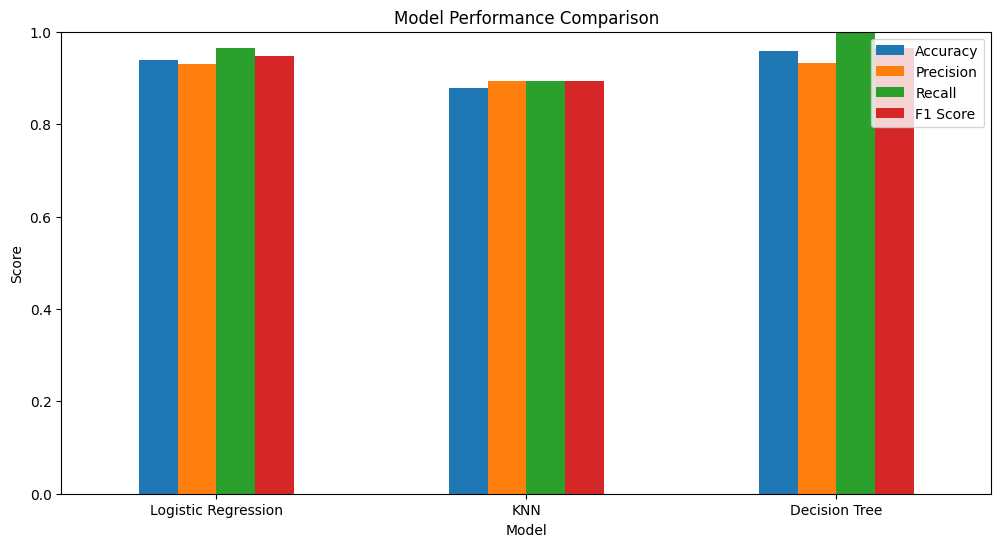

In [60]:
results.set_index("Model")[[
      "Accuracy",
          "Precision",
              "Recall",
                  "F1 Score"
                  ]].plot(
                      kind="bar",
                          figsize=(12,6)
                          )

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)

plt.show()


Confusion matrix: Logistic Regression

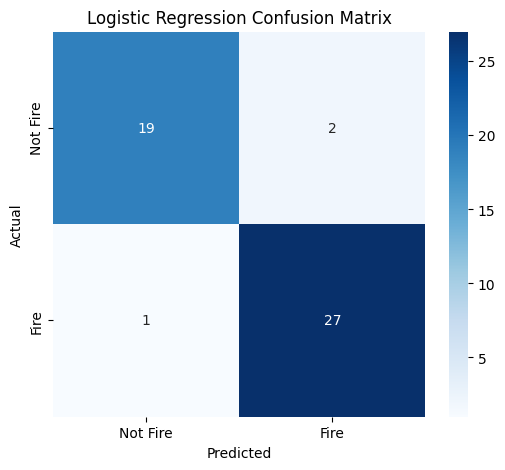

In [62]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_lr,
        annot=True,
            fmt="d",
                cmap="Blues",
                    xticklabels=["Not Fire", "Fire"],
                        yticklabels=["Not Fire", "Fire"]
                        )

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

Confusion matrix: KNN

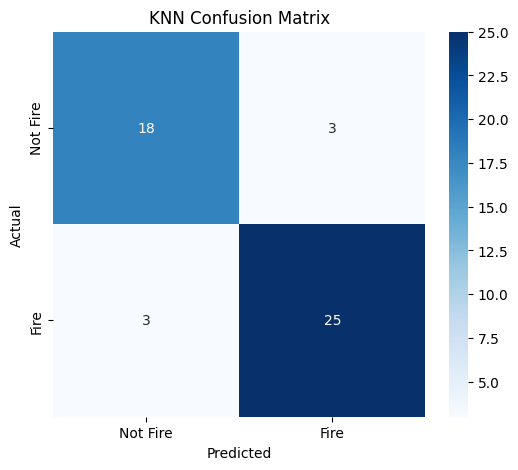

In [64]:
cm_knn = confusion_matrix(y_test, y_pred_knn)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_knn,
        annot=True,
            fmt="d",
                cmap="Blues",
                    xticklabels=["Not Fire", "Fire"],
                        yticklabels=["Not Fire", "Fire"]
                        )

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

Confusion matrix: Decision Tree

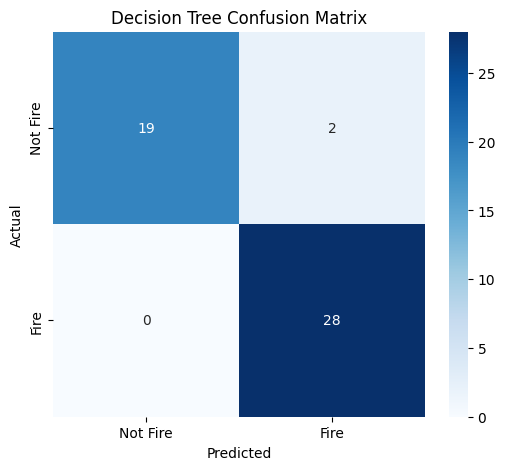

In [66]:
cm_tree = confusion_matrix(y_test, y_pred_tree)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm_tree,
        annot=True,
            fmt="d",
                cmap="Blues",
                    xticklabels=["Not Fire", "Fire"],
                        yticklabels=["Not Fire", "Fire"]
                        )

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

Classification report

In [68]:
print("LOGISTIC REGRESSION")
print(classification_report(
    y_test,
        y_pred_lr,
            target_names=["Not Fire", "Fire"]
            ))

print("\nKNN")
print(classification_report(
                y_test,
                    y_pred_knn,
                        target_names=["Not Fire", "Fire"]
                        ))

print("\nDECISION TREE")
print(classification_report(
                            y_test,
                                y_pred_tree,
                                    target_names=["Not Fire", "Fire"]
                                    ))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

    Not Fire       0.95      0.90      0.93        21
        Fire       0.93      0.96      0.95        28

    accuracy                           0.94        49
   macro avg       0.94      0.93      0.94        49
weighted avg       0.94      0.94      0.94        49


KNN
              precision    recall  f1-score   support

    Not Fire       0.86      0.86      0.86        21
        Fire       0.89      0.89      0.89        28

    accuracy                           0.88        49
   macro avg       0.88      0.88      0.88        49
weighted avg       0.88      0.88      0.88        49


DECISION TREE
              precision    recall  f1-score   support

    Not Fire       1.00      0.90      0.95        21
        Fire       0.93      1.00      0.97        28

    accuracy                           0.96        49
   macro avg       0.97      0.95      0.96        49
weighted avg       0.96      0.96 

 Feature importance

In [72]:
importance = pd.DataFrame({
      "Feature": features,
          "Importance": tree_model.feature_importances_
          })

importance = importance.sort_values(
              by="Importance",
                  ascending=False
                  )

print(importance)


       Feature  Importance
7          ISI    0.958877
1           RH    0.015954
5          DMC    0.013959
4         FFMC    0.011211
0  Temperature    0.000000
3         Rain    0.000000
2           Ws    0.000000
6           DC    0.000000
8          BUI    0.000000
9          FWI    0.000000


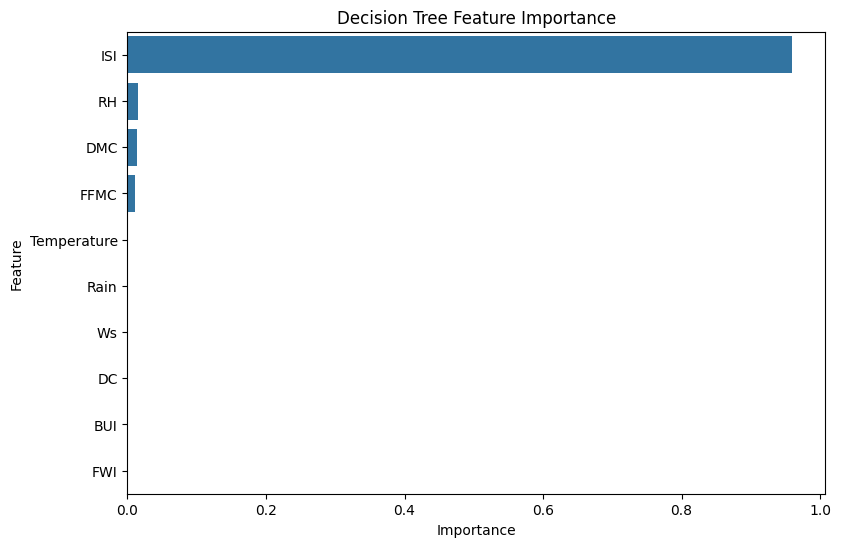

In [74]:
plt.figure(figsize=(9,6))

sns.barplot(
    data=importance,
        x="Importance",
            y="Feature"
            )

plt.title("Decision Tree Feature Importance")

plt.show()

Error analysis

In [76]:
error_analysis = X_test.copy()

error_analysis["Actual"] = y_test
error_analysis["Predicted"] = y_pred_tree

errors = error_analysis[
    error_analysis["Actual"] != error_analysis["Predicted"]
    ]

print("Number of incorrect predictions:", len(errors))

errors.head(20)

Number of incorrect predictions: 2


,Temperature,RH,Ws,Rain,FFMC,DMC,DC,ISI,BUI,FWI,Actual,Predicted
33,33.0,78.0,17.0,0.0,80.1,4.6,18.5,2.7,5.7,1.7,0.0,1.0
36,35.0,64.0,18.0,0.2,80.0,9.7,40.4,2.8,12.1,3.2,0.0,1.0


In [77]:
final_model = tree_model
final_model_name = "Decision Tree"

print("Final model:", final_model_name)

Final model: Decision Tree


Save final model

In [78]:
with open("forest_fire_model.pkl", "wb") as file:
      pickle.dump(final_model, file)

      print("Final model saved successfully!")

Final model saved successfully!


In [79]:
files.download("forest_fire_model.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

 Save feature names

In [80]:
with open("feature_names.pkl", "wb") as file:
      pickle.dump(features, file)

      files.download("feature_names.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

 Save model results

In [82]:
results.to_csv(
      "model_comparison_results.csv",
          index=False
          )

files.download("model_comparison_results.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Test a new observation

In [85]:
new_observation = pd.DataFrame({
      "Temperature": [35],
          "RH": [30],
              "Ws": [18],
                  "Rain": [0],
                      "FFMC": [85],
                          "DMC": [25],
                              "DC": [100],
                                  "ISI": [10],
                                      "BUI": [30],
                                          "FWI": [15]
                                          })

prediction = final_model.predict(new_observation)[0]

if prediction == 1:
    print("Predicted Class: FIRE")
else:
    print("Predicted Class: NOT FIRE")

Predicted Class: FIRE


Probability

In [86]:
probability = final_model.predict_proba(new_observation)[0]

print("Probability of NOT FIRE:", probability[0])
print("Probability of FIRE:", probability[1])

Probability of NOT FIRE: 0.0
Probability of FIRE: 1.0
